Generating Kinodynamic A* Global Plan...
Path generated with 15 via-points.
Running Loop (MPC + CBF Safety Layer)...


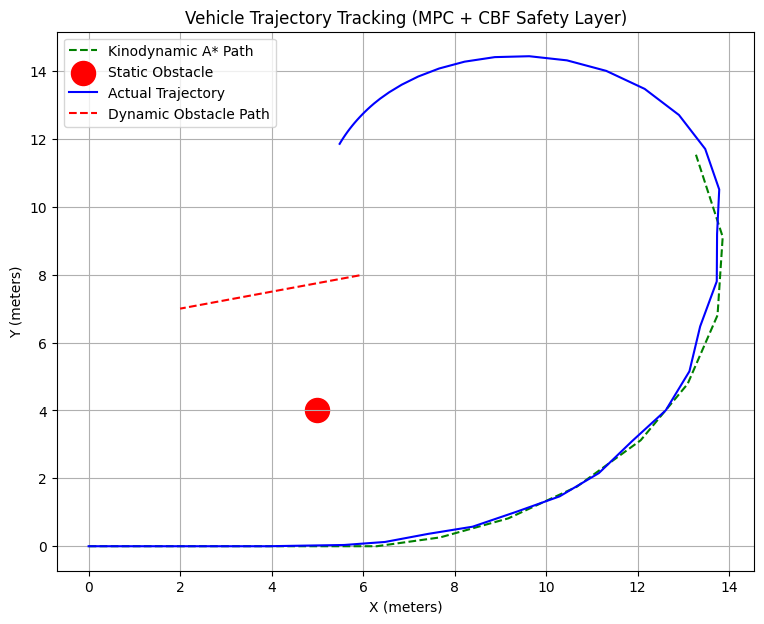

In [4]:
import numpy as np
import scipy.linalg
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import math
import heapq

# =============================================================================
# 1. KINODYNAMIC A* (GLOBAL PATH PLANNER)
# =============================================================================

class Node:
    def __init__(self, x, y, theta, v, g=float('inf'), h=0, parent=None, u=None):
        self.x = x
        self.y = y
        self.theta = theta
        self.v = v
        self.g = g  # Cost to come
        self.h = h  # Heuristic cost
        self.f = g + h
        self.parent = parent
        self.u = u  # Control input (a, delta) that led to this state

    def __lt__(self, other):
        return self.f < other.f

    @property
    def state(self):
        # Reduced quantization sensitivity to avoid premature pruning
        return (round(self.x * 2) / 2, round(self.y * 2) / 2, round(self.theta, 1))

def vehicle_dynamics(state, u, dt=0.2, L=2.5):
    """Bicycle model step simulation."""
    x, y, theta, v = state
    a, delta = u

    x_next = x + v * math.cos(theta) * dt
    y_next = y + v * math.sin(theta) * dt
    theta_next = theta + (v / L) * math.tan(delta) * dt
    v_next = v + a * dt

    # Clip velocity to realistic bounds
    v_next = max(0.5, min(v_next, 10.0))
    return x_next, y_next, theta_next, v_next

def kinodynamic_astar(start_state, goal_pos, obstacles, grid_bounds):
    """
    Kinodynamic A* Planner.
    obstacles: list of tuples (x, y, radius)
    grid_bounds: (min_x, max_x, min_y, max_y)
    """
    start_node = Node(*start_state, g=0, h=math.hypot(start_state[0]-goal_pos[0], start_state[1]-goal_pos[1]))
    open_set = [start_node]
    closed_set = set()

    # Extended action primitives to ensure maneuverability around obstacles
    actions = [
        (2.0, 0.0), (2.0, 0.3), (2.0, -0.3),
        (0.0, 0.0), (0.0, 0.3), (0.0, -0.3),
        (-1.0, 0.0), (-1.0, 0.3), (-1.0, -0.3)
    ]

    while open_set:
        current = heapq.heappop(open_set)

        if math.hypot(current.x - goal_pos[0], current.y - goal_pos[1]) < 2.0:
            # Reconstruct path
            path = []
            while current:
                path.append([current.x, current.y, current.theta, current.v])
                current = current.parent
            return np.array(path[::-1])

        if current.state in closed_set:
            continue
        closed_set.add(current.state)

        for u in actions:
            next_s = vehicle_dynamics((current.x, current.y, current.theta, current.v), u, dt=0.3)

            # Boundary check
            if not (grid_bounds[0] <= next_s[0] <= grid_bounds[1] and grid_bounds[2] <= next_s[1] <= grid_bounds[3]):
                continue

            # Obstacle check
            collision = False
            for ox, oy, r in obstacles:
                if math.hypot(next_s[0] - ox, next_s[1] - oy) < (r + 0.5):
                    collision = True
                    break
            if collision:
                continue

            g_cost = current.g + 0.3  # Step cost
            h_cost = math.hypot(next_s[0] - goal_pos[0], next_s[1] - goal_pos[1])

            neighbor = Node(*next_s, g=g_cost, h=h_cost, parent=current, u=u)
            heapq.heappush(open_set, neighbor)

    return None

# =============================================================================
# 2. MODEL PREDICTIVE CONTROL (LOCAL TRACKER)
# =============================================================================

class MPCController:
    def __init__(self, N=5, dt=0.2):
        self.N = N  # Horizon length
        self.dt = dt

    def objective(self, u_flat, current_state, reference_path):
        """MPC Optimization Cost Function."""
        u = u_flat.reshape((self.N, 2))
        cost = 0.0
        state = current_state

        for i in range(self.N):
            state = vehicle_dynamics(state, u[i], dt=self.dt)

            # Find closest reference index or match index by time step
            ref_idx = min(i, len(reference_path) - 1)
            ref_state = reference_path[ref_idx]

            # Cost weights: Position tracking error + control effort penalty
            cost += 15.0 * (state[0] - ref_state[0])**2
            cost += 15.0 * (state[1] - ref_state[1])**2
            cost += 1.0 * (u[i][0]**2 + u[i][1]**2)

        return cost

    def compute_control(self, current_state, reference_path):
        # Bound constraints for [acceleration, steering]
        bounds = [(-2.0, 2.0), (-0.5, 0.5)] * self.N
        u0 = np.zeros(self.N * 2)

        res = minimize(self.objective, u0, args=(current_state, reference_path),
                       bounds=bounds, method='SLSQP')

        if res.success:
            return res.x[0:2]  # Return the very first control input pair
        return np.array([0.0, 0.0])

# =============================================================================
# 3. SAFETY CORRECTION LAYER (CONTROL BARRIER FUNCTION)
# =============================================================================

def safety_filter_cbf(state, u_nominal, dynamic_obstacles, gamma=0.5, r_safe=1.0):
    """
    Applies a Control Barrier Function (CBF) via a Quadratic Program (QP).
    Ensures safe distance from dynamic obstacles.
    """
    x, y, theta, v = state
    a_nom, delta_nom = u_nominal

    A_mat = []
    b_mat = []

    for ox, oy, vx, vy in dynamic_obstacles:
        # Distance metric
        dx = x - ox
        dy = y - oy
        h = (dx**2 + dy**2) - r_safe**2

        A_row = [-2 * dx * math.cos(theta), -2 * dy * math.sin(theta) * 0.1]
        b_val = gamma * h + 2 * dx * vx + 2 * dy * vy

        A_mat.append(A_row)
        b_mat.append(b_val)

    if not A_mat:
        return u_nominal

    # Solve the QP using SciPy minimize
    def qp_obj(u):
        return 0.5 * np.dot(u - u_nominal, u - u_nominal)

    def constraint_cbf(u):
        # Must return >= 0 values for SciPy constraints
        A = np.array(A_mat)
        b = np.array(b_mat)
        return b - np.dot(A, u)

    cons = {'type': 'ineq', 'fun': constraint_cbf}
    res = minimize(qp_obj, u_nominal, constraints=cons, bounds=[(-2.0, 2.0), (-0.5, 0.5)])

    return res.x

# =============================================================================
# 4. EXECUTION SIMULATION PIPELINE
# =============================================================================

# Environment configs
start = (0.0, 0.0, 0.0, 2.0)  # Initial speed of 2.0 to give the planner more reach
goal = (12.0, 10.0)
static_obstacles = [(5.0, 4.0, 1.2)] # x, y, radius
grid = (0, 15, 0, 15)

print("Generating Kinodynamic A* Global Plan...")
global_path = kinodynamic_astar(start, goal, static_obstacles, grid)

if global_path is None:
    print("Failed to find global path.")
else:
    print(f"Path generated with {len(global_path)} via-points.")

    # Initialize components
    mpc = MPCController(N=4, dt=0.2)
    current_state = np.array(start)
    sim_steps = 50
    history = [current_state]

    # Dynamic obstacle moves horizontally across tracking trajectory
    dynamic_obs = [6.0, 8.0, -0.4, -0.1] # x, y, vx, vy
    obs_history = []

    print("Running Loop (MPC + CBF Safety Layer)...")
    for step in range(sim_steps):
        # Update dynamic obstacle position
        dynamic_obs[0] += dynamic_obs[2] * 0.2
        dynamic_obs[1] += dynamic_obs[3] * 0.2
        obs_history.append((dynamic_obs[0], dynamic_obs[1]))

        # 1. Compute target reference window matching time horizon
        dist_to_path = np.linalg.norm(global_path[:, :2] - current_state[:2], axis=1)
        closest_idx = np.argmin(dist_to_path)
        ref_window = global_path[closest_idx : closest_idx + mpc.N]

        if len(ref_window) < mpc.N:
            # Pad window if close to end of path array
            ref_window = np.vstack([ref_window, [global_path[-1]] * (mpc.N - len(ref_window))])

        # 2. Compute Nominal Tracking Control via MPC
        u_mpc = mpc.compute_control(current_state, ref_window)

        # 3. Intercept & Screen Control via Safety Correction Layer (CBF)
        u_safe = safety_filter_cbf(current_state, u_mpc, [dynamic_obs], gamma=0.8, r_safe=1.2)

        # 4. Step physics (convert tuple back to a NumPy array immediately)
        next_state_raw = vehicle_dynamics(current_state, u_safe, dt=0.2)
        current_state = np.array(next_state_raw)
        history.append(current_state)

        # Terminate early if close enough to destination
        if np.linalg.norm(current_state[:2] - np.array(goal)) < 1.0:
            print(f"Goal successfully reached at step {step}!")
            break

    # Visualization plot
    history = np.array(history)
    obs_history = np.array(obs_history)

    plt.figure(figsize=(9, 7))
    plt.plot(global_path[:, 0], global_path[:, 1], 'g--', label='Kinodynamic A* Path')
    plt.scatter(static_obstacles[0][0], static_obstacles[0][1], s=300, color='red', label='Static Obstacle')
    plt.plot(history[:, 0], history[:, 1], 'b-', label='Actual Trajectory')
    plt.plot(obs_history[:, 0], obs_history[:, 1], 'r--', label='Dynamic Obstacle Path')
    plt.xlabel('X (meters)')
    plt.ylabel('Y (meters)')
    plt.title('Vehicle Trajectory Tracking (MPC + CBF Safety Layer)')
    plt.legend()
    plt.grid(True)
    plt.show()
